In [1]:
# conda vis2
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
import src.Retrieval as retrieval
from src.utils.util import set_labels
from src.ExperimentSet import ExperimentSet

In [3]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11'
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [17]:
list(exset.retrievals.values())[7].cvm

<xarray.Dataset>
Dimensions:            (x: 65, y: 65, z: 15)
Coordinates:
  * x                  (x) float64 0.0 0.275 0.55 0.825 ... 17.05 17.33 17.6
  * y                  (y) float64 0.0 0.275 0.55 0.825 ... 17.05 17.33 17.6
  * z                  (z) float64 0.0 0.1 0.2 0.3 0.4 ... 1.0 1.1 1.2 1.3 1.4
Data variables:
    delx               float64 0.275
    dely               float64 0.275
    lcl                (x, y, z) int64 0 0 0 0 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1 1
    cth                (x, y, z) int64 1 1 1 1 1 1 1 1 0 0 ... 1 0 0 0 0 0 0 0 0
    sc                 (x, y, z) int64 1 1 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1 1
    encoded            (x, y, z) int64 6 6 6 6 7 7 7 7 5 5 ... 7 5 5 5 5 5 5 5 5
    cloud_volume_mask  (x, y, z) int64 0 0 0 0 1 1 1 1 0 0 ... 1 0 0 0 0 0 0 0 0

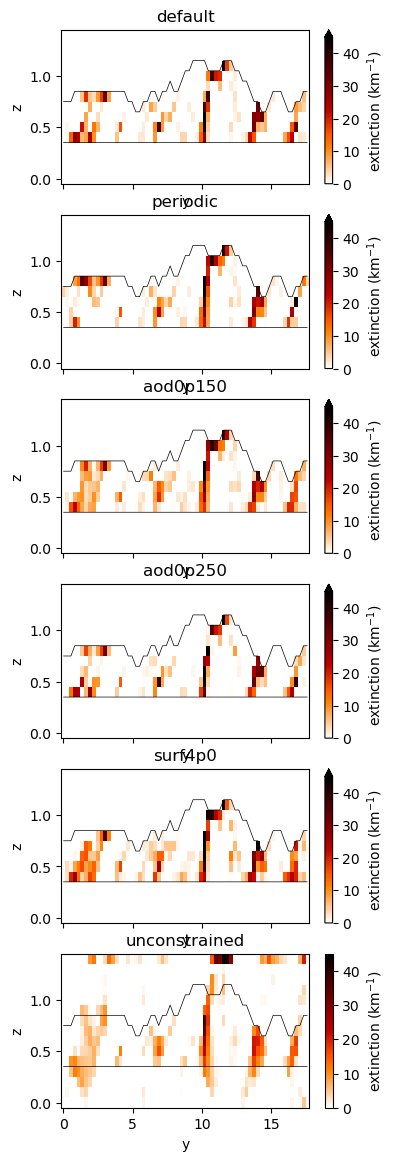

In [18]:
plot_kwargs = {
    'y':'z',
    'vmin': 0,
    'vmax': 45,
    'cmap': 'gist_heat_r',
    'cbar_kwargs': {'label': r'extinction (km$^{-1}$)'}
}
contour_kwargs = {
    'y':'z',
    'levels': 1,
    'colors': 'black',
    'linewidths': 0.5
}
x = 3.3
sublist = ['default', 'periodic', 'aod0p150', 'aod0p250', 'surf4p0', 'unconstrained']
r_defalut = list(exset.retrievals.values())[7]
assert r_defalut.exp_name == 'default'
cvm = r_defalut.cvm
f, ax = plt.subplots(len(sublist), 1, figsize=(4, 14), sharex=True, sharey=True)
for r in exset.retrievals.values():
    if(r.exp_name in sublist):
        i = sublist.index(r.exp_name)
        cloud = r.solvers_retrieval[0.67].medium['cloud']
        cloud.sel(x=x, method='nearest').extinction.plot(ax=ax[i], **plot_kwargs)
        cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(ax=ax[i], **contour_kwargs)
        ax[i].set_title(r.exp_name)

In [7]:
r.cvm

<xarray.Dataset>
Dimensions:            (x: 65, y: 65, z: 15)
Coordinates:
  * x                  (x) float64 0.0 0.275 0.55 0.825 ... 17.05 17.33 17.6
  * y                  (y) float64 0.0 0.275 0.55 0.825 ... 17.05 17.33 17.6
  * z                  (z) float64 0.0 0.1 0.2 0.3 0.4 ... 1.0 1.1 1.2 1.3 1.4
Data variables:
    delx               float64 0.275
    dely               float64 0.275
    lcl                (x, y, z) int64 0 0 0 0 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1 1
    cth                (x, y, z) int64 1 1 1 1 1 1 1 1 0 0 ... 1 0 0 0 0 0 0 0 0
    sc                 (x, y, z) int64 1 1 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1 1
    encoded            (x, y, z) int64 6 6 6 6 7 7 7 7 5 5 ... 7 5 5 5 5 5 5 5 5
    cloud_volume_mask  (x, y, z) int64 0 0 0 0 1 1 1 1 0 0 ... 1 0 0 0 0 0 0 0 0

In [ ]:
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V10' / 'default'
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V10' / 'HBC' / 'periodic' # Odd retrieval
# EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'CVM' / 'unconstrained'
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11' / 'default'
r = retrieval.Retrieval(EXPERIMENT)
r.load_retrieval()

FIGURE_OUT = EXPERIMENT / 'figures'
FIGURE_OUT.mkdir(parents=True, exist_ok=True)

In [ ]:
ext_cmap = 'gist_heat_r'
x = 4.4
vmax = None
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
cloud = r.solvers_retrieval[0.67].medium['cloud']
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 2, figsize=(10, 3.5))
cloud.sel(x=x, method='nearest').extinction.plot(
    y='z',
    ax=ax[0],
    vmin=0,
    vmax=vmax,
    cmap=ext_cmap,
    cbar_kwargs={'label': r'extionction (km$^{-1}$)'}
)
r.cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(
    y='z',
    levels=1, 
    ax=ax[0],
    colors='black',
    linewidths=0.5
)
ax[0].set_xlabel('y (km)')
ax[0].set_ylabel('z (km)')
ax[0].set_title('x = 4.4 km')
c = ax[1].tricontourf(
    r.obs['MISR']['sensor_list'][4].cam_x.data,
    r.obs['MISR']['sensor_list'][4].cam_y.data,
    r.obs['MISR']['sensor_list'][4].brf.data,
    cmap = 'gray',
    vmin = 0,
    vmax = 0.4,
    levels = np.linspace(0, 0.4, 100)
)
plt.colorbar(c, ax=ax[1], label='BRF', ticks=[0.0, 0.1, 0.2, 0.3, 0.4])

ax[1].vlines(x, 0, 17.6, colors='red')
ax[1].set_xlabel('x (km)')
ax[1].set_ylabel('y (km)')
ax[1].set_title('MISR nadir')
ax[0].set_xticks(ticks)
ax[1].set_xticks(ticks)
ax[1].set_yticks(ticks)

set_labels(ax.flatten())